In [ ]:
from model import OpenCoverModel
import pickle
import pandas as pd
from tqdm import tqdm
from sparse_batch_run import sparse_batch_run

# === Simulation Parameters ===
behavior = "part"  # options: "pure_levy", "truncated_levy", "composite_levy", "biased_composite", "resource_aware", "comparative_rewards", "all", "nearest_flower", "levy_flight"
landing_prob = 1.0
n_agents = 60
iterations = 3            # Number of repetitions per setting (each with a different seed)
steps = 5 * 60 * 60       # Total number of simulation steps. Past values: (3 * 60 * 60)
num_processes = 10         # Use None for all CPUs
replenish_rate = 0
interval = 10 * 60        # Saving at every 10 minutes

In [ ]:
# === Determine which behaviors to run ===
if behavior == "all":
    behaviors_to_run = ["pure_levy", "truncated_levy", "composite_levy", "biased_composite", "resource_aware", "comparative_rewards", "nearest_flower", "levy_flight"]
elif behavior == "part":
    behaviors_to_run = ["resource_aware", "comparative_rewards", "levy_flight"]
else:
    behaviors_to_run = [behavior]

# === Run simulations ===
for b in behaviors_to_run:
    print(f"\n=== Running behavior: {b} ===\n")

    # Batch parameters
    param_dict = {
        "n_agents": n_agents,
        "bee_behavior": b,
        "landing_prob": landing_prob,
        "seed": range(iterations),
        "replenish_rate": replenish_rate,
        "interval": interval,
    }

    results = sparse_batch_run(
        model_cls=OpenCoverModel,
        parameters=param_dict,
        iterations=1,
        max_steps=steps,
        number_processes=num_processes,
        # data_collection_period= 1,
        display_progress=True
    )
    

    # Save output
    df = pd.DataFrame(results)
    output_filename = f"batch_results_{b}.pkl"
    with open(output_filename, "wb") as f:
        pickle.dump(results, f)

    print(f"Simulation complete. Results saved to {output_filename}")


=== Running behavior: resource_aware ===



  0%|          | 0/3 [00:00<?, ?it/s]

## Investigating saved data

In [3]:
# ==== Inspect saved batch results (sparse_batch_run outputs) ====

import pickle, os, sys, math
import pandas as pd
import numpy as np
from pathlib import Path

# ---------- 1) Loader ----------
def load_batch_results(pkl_path: str) -> pd.DataFrame:
    """
    Loads a pickle created by sparse_batch_run (list[dict]) and returns a DataFrame.
    If the pickle already contains a DataFrame, it just returns it.
    """
    with open(pkl_path, "rb") as f:
        obj = pickle.load(f)
    if isinstance(obj, pd.DataFrame):
        df = obj.copy()
    elif isinstance(obj, list):
        df = pd.DataFrame(obj)
    else:
        raise TypeError(f"Unsupported pickle content: {type(obj)}")
    # Normalize Step to int if present
    if "Step" in df.columns:
        df["Step"] = df["Step"].astype(int)
    return df


# ---------- 2) Quick summary ----------
def quick_summary(df: pd.DataFrame, max_cols_show=40):
    print("=== Shape ===")
    print(df.shape)

    print("\n=== Columns ===")
    cols = list(df.columns)
    if len(cols) > max_cols_show:
        head = cols[:max_cols_show]
        tail = cols[-5:]
        print(head, " ... ", tail)
    else:
        print(cols)

    print("\n=== Dtypes ===")
    print(df.dtypes.sort_index())

    # Common fields sparse_batch_run should produce
    for col in ["RunId", "iteration", "seed", "bee_behavior", "Behavior", "Step", "Agent Type", "AgentID", "unique_id"]:
        if col in df.columns:
            uniq = df[col].dropna().unique()
            preview = uniq[:15]
            print(f"\n• {col}: {len(uniq)} unique → {preview}{' ...' if len(uniq) > 15 else ''}")

    if "Step" in df.columns:
        print(f"\nStep range: {df['Step'].min()} → {df['Step'].max()}")
        gaps = np.diff(np.sort(df['Step'].unique()))
        if len(gaps):
            print(f"Step deltas (unique): {np.unique(gaps)}")

    if "Agent Type" in df.columns:
        print("\nAgent Type counts (top 10):")
        print(df["Agent Type"].value_counts().head(10))

    # Memory footprint
    print("\n=== Memory usage (approx) ===")
    print(df.memory_usage(deep=True).sum() / 1e6, "MB total")


# ---------- 3) Check sampling interval (per run) ----------
def check_sampling_interval(df: pd.DataFrame):
    """
    Prints the unique step deltas per (RunId, seed) to confirm your model-side interval sampling.
    """
    if not {"RunId", "Step"}.issubset(df.columns):
        print("RunId/Step not found.")
        return
    deltas_by_run = {}
    for (rid, s), grp in df.groupby(["RunId", "seed"], dropna=False):
        steps = np.sort(grp["Step"].unique())
        if len(steps) >= 2:
            deltas_by_run[(rid, s)] = tuple(sorted(set(np.diff(steps))))
    # Show a compact summary
    seen = {}
    for k, v in deltas_by_run.items():
        seen.setdefault(v, 0)
        seen[v] += 1
    print("Unique step-delta patterns across runs (pattern: count):")
    for pattern, count in seen.items():
        print(f"  {pattern}: {count} runs")


# ---------- 4) Peek agent vs model rows ----------
def split_agent_model_rows(df: pd.DataFrame):
    """
    Returns (agent_rows, model_rows) helpers.
    Agent rows usually have 'Agent Type' present; model-only rows do not.
    """
    has_agent_type = df["Agent Type"].notna() if "Agent Type" in df.columns else pd.Series(False, index=df.index)
    return df[has_agent_type].copy(), df[~has_agent_type].copy()


# ---------- 5) Show examples per Agent Type ----------
def show_examples(df: pd.DataFrame, agent_type="plant", n=5):
    if "Agent Type" not in df.columns:
        print("No 'Agent Type' column.")
        return
    sub = df[df["Agent Type"] == agent_type]
    if sub.empty:
        print(f"No rows with Agent Type == '{agent_type}'.")
        return
    print(f"\n=== {agent_type.upper()} examples (n={min(n, len(sub))}) ===")
    display(sub.head(n))


# ---------- 6) Inspect nested/list-like columns you care about ----------
NESTED_CANDIDATES = [
    "Position",
    "Plant visit timestamp",
    "Bee latest visited plant",
    "Bee latest visited plant step",
]

def inspect_nested_columns(df: pd.DataFrame, max_show=3):
    for col in NESTED_CANDIDATES:
        if col not in df.columns:
            continue
        ser = df[col].dropna()
        if ser.empty:
            print(f"\n{col}: present but all NaN/empty.")
            continue
        kinds = ser.apply(lambda x: type(x).__name__).value_counts()
        print(f"\n{col}: value types\n{kinds}")
        # show sample non-empty values
        examples = ser.head(max_show).tolist()
        print(f"{col}: examples →")
        for ex in examples:
            print("  ", ex)


# ---------- 7) Group helpers often needed for plots ----------
def group_counts(df: pd.DataFrame):
    if {"Agent Type", "Step"}.issubset(df.columns):
        g = df.groupby(["Step", "Agent Type"]).size().unstack("Agent Type").fillna(0).astype(int)
        print("\nCounts per Step × Agent Type (head):")
        display(g.head())
    if {"seed", "RunId"}.issubset(df.columns):
        print("\nRuns summary:")
        display(df.groupby(["RunId", "seed"]).size().to_frame("rows").head())


# ---------- 8) Call on one or both files ----------
behavior_a = "comparative_rewards"
behavior_b = "resource_aware"

paths = [
    f"batch_results_{behavior_a}.pkl",
    f"batch_results_{behavior_b}.pkl",
]

for p in paths:
    if not Path(p).exists():
        print(f"WARNING: {p} not found, skipping.")
        continue
    print("\n" + "="*80)
    print(f"FILE: {p}")
    df = load_batch_results(p)

    quick_summary(df)
    check_sampling_interval(df)

    agent_rows, model_rows = split_agent_model_rows(df)
    print(f"\nAgent rows: {len(agent_rows)}  |  Model-only rows: {len(model_rows)}")

    # Glance at each agent type
    for at in ["bee", "plant", "beehive"]:
        show_examples(agent_rows, agent_type=at, n=5)

    # Peek nested/list-like columns
    inspect_nested_columns(agent_rows)

    # Common group summaries
    group_counts(df)


FILE: batch_results_comparative_rewards.pkl
=== Shape ===
(93309, 26)

=== Columns ===
['RunId', 'iteration', 'Step', 'n_agents', 'bee_behavior', 'landing_prob', 'seed', 'replenish_rate', 'interval', 'Interval', 'Behavior', 'Replenish', 'RewardSize', 'AgentID', 'Position', 'Agent Type', 'unique_id', 'Forage Timer', 'Plot Code', 'Plant visit timestamp', 'BeeHive ID', 'Plant visited this step', 'Plant nectar amount', 'Plant scent timer', 'Bee latest visited plant', 'Bee latest visited plant step']

=== Dtypes ===
Agent Type                        object
AgentID                            int64
Bee latest visited plant          object
Bee latest visited plant step     object
BeeHive ID                       float64
Behavior                          object
Forage Timer                     float64
Interval                           int64
Plant nectar amount              float64
Plant scent timer                float64
Plant visit timestamp             object
Plant visited this step        

,RunId,iteration,Step,n_agents,bee_behavior,landing_prob,seed,replenish_rate,interval,Interval,...,unique_id,Forage Timer,Plot Code,Plant visit timestamp,BeeHive ID,Plant visited this step,Plant nectar amount,Plant scent timer,Bee latest visited plant,Bee latest visited plant step
1,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,2,0.0,"{'color': 'white', 'edgecolors': 'none'}",[],0.0,False,NaN,NaN,[],"[10619, 10620, 10621, 10622, 10623]"
2,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,3,0.0,"{'color': 'white', 'edgecolors': 'none'}",[],0.0,False,NaN,NaN,[],"[10796, 10797, 10798, 10799, 10800]"
3,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,4,0.0,"{'color': 'white', 'edgecolors': 'none'}",[],0.0,False,NaN,NaN,[],"[10771, 10772, 10773, 10774, 10775]"
4,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,5,0.0,"{'color': 'white', 'edgecolors': 'none'}",[],0.0,False,NaN,NaN,[],"[10779, 10780, 10781, 10782, 10783]"
5,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,6,0.0,"{'color': 'white', 'edgecolors': 'none'}",[],0.0,False,NaN,NaN,[],"[10797, 10798, 10799, 10800, 10801]"



=== PLANT examples (n=5) ===


,RunId,iteration,Step,n_agents,bee_behavior,landing_prob,seed,replenish_rate,interval,Interval,...,unique_id,Forage Timer,Plot Code,Plant visit timestamp,BeeHive ID,Plant visited this step,Plant nectar amount,Plant scent timer,Bee latest visited plant,Bee latest visited plant step
122,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,123,NaN,"{'color': 'blue', 'edgecolors': 'none'}",[],NaN,False,13.0,0.0,[],None
123,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,124,NaN,"{'color': 'blue', 'edgecolors': 'none'}",[],NaN,False,13.0,0.0,[],None
124,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,125,NaN,"{'color': 'blue', 'edgecolors': 'none'}",[],NaN,False,13.0,0.0,[],None
125,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,126,NaN,"{'color': 'blue', 'edgecolors': 'none'}",[],NaN,False,13.0,0.0,[],None
126,1,0,0,60,comparative_rewards,1.0,1,0,600,600,...,127,NaN,"{'color': 'blue', 'edgecolors': 'none'}",[],NaN,False,13.0,0.0,[],None



=== BEEHIVE examples (n=5) ===


...

,RunId,iteration,Step,n_agents,bee_behavior,landing_prob,seed,replenish_rate,interval,Interval,...,unique_id,Forage Timer,Plot Code,Plant visit timestamp,BeeHive ID,Plant visited this step,Plant nectar amount,Plant scent timer,Bee latest visited plant,Bee latest visited plant step
0,1,0,0,60,resource_aware,1.0,1,0,600,600,...,1,NaN,"{'color': 'brown', 'edgecolors': 'none'}",[],NaN,False,NaN,NaN,[],None
61,1,0,0,60,resource_aware,1.0,1,0,600,600,...,62,NaN,"{'color': 'brown', 'edgecolors': 'none'}",[],NaN,False,NaN,NaN,[],None
1637,1,0,600,60,resource_aware,1.0,1,0,600,600,...,1,NaN,"{'color': 'brown', 'edgecolors': 'none'}",[],NaN,False,NaN,NaN,[],None
1698,1,0,600,60,resource_aware,1.0,1,0,600,600,...,62,NaN,"{'color': 'brown', 'edgecolors': 'none'}",[],NaN,False,NaN,NaN,[],None
3274,1,0,1200,60,resource_aware,1.0,1,0,600,600,...,1,NaN,"{'color': 'brown', 'edgecolors': 'none'}",[],NaN,False,NaN,NaN,[],None



Position: value types
Position
tuple    93309
Name: count, dtype: int64
Position: examples →
   (5, 5.7)
   (5, 5.7)
   (5, 5.7)

Plant visit timestamp: value types
Plant visit timestamp
list    93309
Name: count, dtype: int64
Plant visit timestamp: examples →
   []
   []
   []

Bee latest visited plant: value types
Bee latest visited plant
list    93309
Name: count, dtype: int64
Bee latest visited plant: examples →
   []
   []
   []

Bee latest visited plant step: value types
Bee latest visited plant step
deque    6840
Name: count, dtype: int64
Bee latest visited plant step: examples →
   deque([10684, 10685, 10686, 10687, 10688], maxlen=5)
   deque([10788, 10789, 10790, 10800, 10801], maxlen=5)
   deque([10794, 10795, 10796, 10797, 10798], maxlen=5)

Counts per Step × Agent Type (head):


Agent Type,bee,beehive,plant
Step,,,
0,360,6,4545
600,360,6,4545
1200,360,6,4545
1800,360,6,4545
2400,360,6,4545



Runs summary:


,,rows
RunId,seed,
0,0,31103
1,1,31103
2,2,31103


# Loading dataframes

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

behaviors = ["comparative_rewards", "resource_aware", "nearest_flower", "levy_flight"]
dfs_by_behavior = {}
for b in behaviors:
    fn = f"batch_results_{b}.pkl"
    sim_runs = pd.read_pickle(fn)
    dfs_by_behavior[b] = pd.DataFrame(sim_runs)

# Animating average number of bee visits and remaining nectar

In [5]:
# # The following code works for two behaviors

# from collections import deque

# # ----------------------------
# # Helpers (sparse-aware)
# # ----------------------------
# CANON_MAP = {
#     "interval": "interval",
#     "Interval": "interval",
#     "bee_behavior": "behavior",
#     "Behavior": "behavior",
#     "replenish_rate": "replenish_rate",
#     "Replenish": "replenish_rate",
#     "RewardSize": "reward_size",
# }

# def canonicalize_cols(df: pd.DataFrame) -> pd.DataFrame:
#     df = df.copy()
#     for src, dst in CANON_MAP.items():
#         if src in df.columns and dst not in df.columns:
#             df[dst] = df[src]
#     # Optionally drop duplicates (keeps the canonical names)
#     for src, dst in CANON_MAP.items():
#         if src in df.columns and src != dst:
#             df.drop(columns=[src], inplace=True, errors="ignore")
#     if "Step" in df.columns:
#         df["Step"] = df["Step"].astype(int)
#     return df

# def split_by_type(df: pd.DataFrame):
#     return (
#         df[df["Agent Type"] == "bee"].copy(),
#         df[df["Agent Type"] == "plant"].copy(),
#         df[df["Agent Type"] == "beehive"].copy(),
#     )

# def plant_snapshots(plants: pd.DataFrame) -> pd.DataFrame:
#     out = plants[["RunId","seed","Step","unique_id","Position","Plant nectar amount","Plant visit timestamp"]].copy()
#     out[["x","y"]] = out["Position"].apply(pd.Series)
#     out["Column"] = out["x"]
#     out.rename(columns={"Plant nectar amount":"nectar",
#                         "Plant visit timestamp":"timestamps"}, inplace=True)
#     return out

# def count_recent_visits(timestamps, current_step, window=300):
#     if not isinstance(timestamps, (list, tuple, deque)):
#         return 0
#     lo = current_step - window
#     return sum(lo < ts <= current_step for ts in timestamps)

# def per_column_aggregates(plant_ss: pd.DataFrame, steps=None, window=300):
#     if steps is None:
#         steps = sorted(plant_ss["Step"].unique())

#     # Nectar per column (avg across seeds)
#     nectar_rows = []
#     for step in steps:
#         sub = plant_ss[plant_ss["Step"] == step]
#         per_run = sub.groupby(["Column","seed"], as_index=False)["nectar"].sum()
#         avg_tot = per_run.groupby("Column", as_index=False)["nectar"].mean()
#         avg_tot.rename(columns={"nectar":"Avg Total Nectar"}, inplace=True)
#         avg_tot["Step"] = step
#         nectar_rows.append(avg_tot[["Step","Column","Avg Total Nectar"]])
#     avg_total_nectar = pd.concat(nectar_rows, ignore_index=True)

#     # Visits per minute (avg across seeds) with CI
#     visit_rows = []
#     for step in steps:
#         sub = plant_ss[plant_ss["Step"] == step].copy()
#         sub["Recent Visits"] = sub["timestamps"].apply(lambda ts: count_recent_visits(ts, step, window=window))
#         per_run = sub.groupby(["Column","seed"], as_index=False)["Recent Visits"].sum()
#         g = per_run.groupby("Column")["Recent Visits"]
#         stats = g.agg(['mean','std','count']).reset_index()
#         stats["AvgBeeVisitsPerMinute"] = stats["mean"] / (window/60.0)
#         stats["CI95"] = 1.96 * (stats["std"] / np.sqrt(stats["count"])) / (window/60.0)
#         stats["Step"] = step
#         visit_rows.append(stats[["Step","Column","AvgBeeVisitsPerMinute","CI95"]])
#     avg_visits_df = pd.concat(visit_rows, ignore_index=True)

#     return avg_visits_df, avg_total_nectar

# def prepare_behavior_df(df: pd.DataFrame):
#     df = canonicalize_cols(df)
#     _, plants, _ = split_by_type(df)
#     pss = plant_snapshots(plants)
#     steps = sorted(pss["Step"].unique())  # these are already sparse (e.g., every 600)
#     avg_visits_df, avg_total_nectar = per_column_aggregates(pss, steps=steps, window=300)
#     merged = []
#     for step in steps:
#         m = pd.merge(
#             avg_visits_df[avg_visits_df["Step"] == step],
#             avg_total_nectar[avg_total_nectar["Step"] == step],
#             on=["Step","Column"],
#             how="inner",
#         ).sort_values("Column")
#         merged.append(m)
#     return {"merged": merged, "avg_visits_df": avg_visits_df, "avg_total_nectar": avg_total_nectar}

# def step_to_time_str(step):
#     hh = 10 + step // 3600
#     mm = (step % 3600) // 60
#     return f"{hh}:{mm:02d} am"

# # ----------------------------
# # Prep both behaviors already in memory
# # ----------------------------
# if len(behaviors) < 2:
#     raise ValueError("Provide at least two behaviors in `behaviors` to compare.")

# b1, b2 = behaviors[:2]
# res1 = prepare_behavior_df(dfs_by_behavior[b1])
# res2 = prepare_behavior_df(dfs_by_behavior[b2])

# merged_data1, merged_data2 = res1["merged"], res2["merged"]

# # Shared y-limits
# all_visits = pd.concat([res1["avg_visits_df"]["AvgBeeVisitsPerMinute"],
#                         res2["avg_visits_df"]["AvgBeeVisitsPerMinute"]])
# all_ci = pd.concat([res1["avg_visits_df"]["CI95"],
#                     res2["avg_visits_df"]["CI95"]])
# ymin_visits = max(0, (all_visits - all_ci).min())
# ymax_visits = (all_visits + all_ci).max()

# all_nectar = pd.concat([res1["avg_total_nectar"]["Avg Total Nectar"],
#                         res2["avg_total_nectar"]["Avg Total Nectar"]])
# ymin_nectar, ymax_nectar = 0, all_nectar.max()

# # ----------------------------
# # Animation
# # ----------------------------
# from matplotlib.animation import FuncAnimation
# from IPython.display import HTML

# fig = plt.figure(figsize=(10,5))

# def update(frame_idx):
#     fig.clf()
#     ax1 = fig.add_subplot(111)
#     ax2 = ax1.twinx()

#     merged1 = merged_data1[frame_idx]
#     merged2 = merged_data2[frame_idx]
#     step = int(merged1["Step"].iloc[0])
#     time_str = step_to_time_str(step)

#     # Nectar bars (two sets, side by side)
#     width = 0.4
#     ax2.bar(merged1["Column"]-0.2, merged1["Avg Total Nectar"], width=width,
#             color="blue", edgecolor="black", alpha=0.3, label=f"Nectar {b1}")
#     ax2.bar(merged2["Column"]+0.2, merged2["Avg Total Nectar"], width=width,
#             color="green", edgecolor="black", alpha=0.3, label=f"Nectar {b2}")
#     ax2.set_ylabel("Avg Total Nectar")
#     ax2.set_ylim(ymin_nectar, ymax_nectar)

#     # Visits (lines + CI)
#     ax1.fill_between(merged1["Column"],
#                      merged1["AvgBeeVisitsPerMinute"]-merged1["CI95"],
#                      merged1["AvgBeeVisitsPerMinute"]+merged1["CI95"],
#                      color="orange", alpha=0.2)
#     ax1.plot(merged1["Column"], merged1["AvgBeeVisitsPerMinute"],
#              color="orange", marker='o', label=f"Visits {b1}")

#     ax1.fill_between(merged2["Column"],
#                      merged2["AvgBeeVisitsPerMinute"]-merged2["CI95"],
#                      merged2["AvgBeeVisitsPerMinute"]+merged2["CI95"],
#                      color="red", alpha=0.2)
#     ax1.plot(merged2["Column"], merged2["AvgBeeVisitsPerMinute"],
#              color="red", marker='s', label=f"Visits {b2}")

#     ax1.set_ylabel("Avg Bee Visits/min")
#     ax1.set_ylim(ymin_visits, ymax_visits)
#     ax1.set_xlabel("Column (x-position)")

#     xticks = [x for x in merged1["Column"].unique() if (x % 10 == 0)]
#     if xticks:
#         ax1.set_xticks(xticks)

#     ax1.set_title(f"Avg Bee Visits & Nectar — {time_str} (step {step})")
#     ax1.legend(loc="upper left")
#     ax2.legend(loc="upper right")
#     ax1.grid(True, linestyle='--', alpha=0.7)
#     fig.tight_layout()

# frames = min(len(merged_data1), len(merged_data2))
# anim = FuncAnimation(fig, update, frames=frames, interval=1000, repeat=False)
# HTML(anim.to_jshtml())


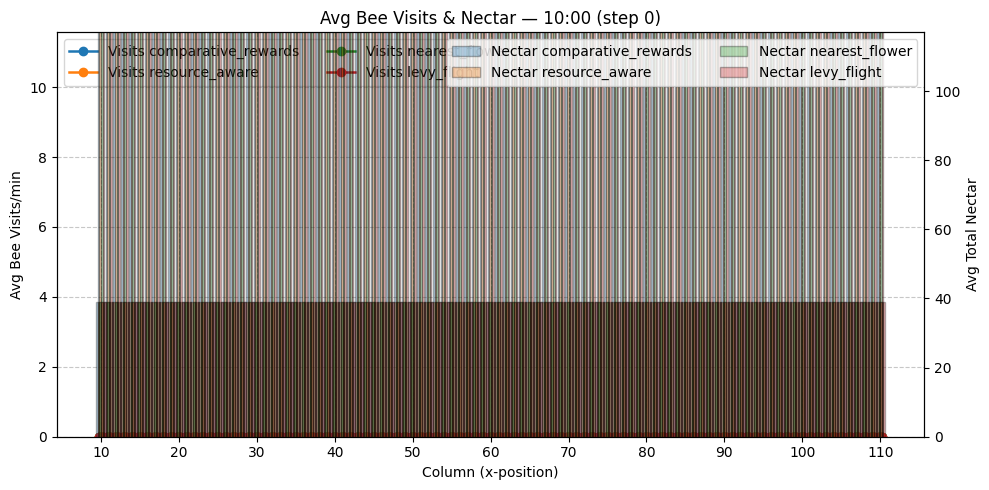

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# ---- Helpers from earlier ----
CANON_MAP = {
    "interval": "interval",
    "Interval": "interval",
    "bee_behavior": "behavior",
    "Behavior": "behavior",
    "replenish_rate": "replenish_rate",
    "Replenish": "replenish_rate",
    "RewardSize": "reward_size",
}
def canonicalize_cols(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for src, dst in CANON_MAP.items():
        if src in df.columns and dst not in df.columns:
            df[dst] = df[src]
    for src, dst in CANON_MAP.items():
        if src in df.columns and src != dst:
            df.drop(columns=[src], inplace=True, errors="ignore")
    if "Step" in df.columns:
        df["Step"] = df["Step"].astype(int)
    return df

def step_to_time_str(step):
    hh = 10 + step // 3600
    mm = (step % 3600) // 60
    return f"{hh}:{mm:02d}"

# ---- Preprocess all behaviors → visits & nectar per column, per step ----
def preprocess_visits_and_nectar(df):
    df = canonicalize_cols(df)
    plant_df = df[df["Agent Type"] == "plant"].copy()
    plant_df["Column"] = plant_df["Position"].apply(lambda pos: pos[0] if isinstance(pos, (list, tuple)) else None)
    plant_df = plant_df.dropna(subset=["Column", "seed"])

    # Nectar (sum per column per run, then mean across runs)
    plant_df_nectar = plant_df.dropna(subset=["Plant nectar amount"]).copy()
    per_run_totals = (
        plant_df_nectar.groupby(["Step", "Column", "seed"])["Plant nectar amount"]
        .sum().reset_index(name="Total Nectar Per Run")
    )
    avg_total_nectar = (
        per_run_totals.groupby(["Step", "Column"])["Total Nectar Per Run"]
        .mean().reset_index(name="Avg Total Nectar")
    )

    # Visits in last 5 min (300s)
    plant_df_visits = plant_df.dropna(subset=["Plant visit timestamp"]).copy()

    def count_recent(ts, current_step):
        if not isinstance(ts, (list, tuple)):
            return 0
        return sum((current_step - 300) < t <= current_step for t in ts)

    timesteps = np.sort(plant_df["Step"].unique())
    visit_rows = []
    for step in timesteps:
        step_df = plant_df_visits[plant_df_visits["Step"] == step].copy()
        if step_df.empty:
            continue
        step_df["Recent Visits"] = step_df["Plant visit timestamp"].apply(lambda ts: count_recent(ts, step))
        per_run = (
            step_df.groupby(["Column", "seed"])["Recent Visits"]
            .sum().reset_index(name="TotalVisitsPerRun")
        )
        grouped = per_run.groupby("Column")["TotalVisitsPerRun"]
        stats = grouped.agg(['mean','std','count']).reset_index()
        stats.rename(columns={"mean":"AvgVisitsAcrossRuns","std":"StdDev","count":"NumRuns"}, inplace=True)
        stats["AvgBeeVisitsPerMinute"] = stats["AvgVisitsAcrossRuns"] / 5.0
        stats["CI95"] = np.where(
            stats["NumRuns"] > 0,
            1.96 * (stats["StdDev"] / np.sqrt(stats["NumRuns"])) / 5.0,
            0.0
        )
        stats["Step"] = step
        visit_rows.append(stats[["Step","Column","AvgBeeVisitsPerMinute","CI95"]])

    avg_visits_df = pd.concat(visit_rows, ignore_index=True) if visit_rows else pd.DataFrame(
        columns=["Step","Column","AvgBeeVisitsPerMinute","CI95"]
    )

    # Merge per-step
    merged_by_step = {}
    for step in np.sort(np.intersect1d(avg_total_nectar["Step"].unique(),
                                       avg_visits_df["Step"].unique())):
        nectar_sub = avg_total_nectar[avg_total_nectar["Step"] == step]
        visits_sub = avg_visits_df[avg_visits_df["Step"] == step]
        merged = pd.merge(visits_sub, nectar_sub, on=["Step","Column"], how="inner").sort_values("Column")
        merged_by_step[step] = merged
    return merged_by_step, avg_visits_df, avg_total_nectar

# Build per-behavior processed dicts
processed = {}
for beh, df in dfs_by_behavior.items():
    merged_by_step, visits_df, nectar_df = preprocess_visits_and_nectar(df)
    processed[beh] = dict(merged_by_step=merged_by_step, visits_df=visits_df, nectar_df=nectar_df)

# Common step list across behaviors
all_steps = sorted(set().union(*[set(p["merged_by_step"].keys()) for p in processed.values()]))

# Y-limits across all behaviors
all_visits_vals = []
all_visits_ci   = []
all_nectar_vals = []
for beh in processed:
    vdf = processed[beh]["visits_df"]
    ndf = processed[beh]["nectar_df"]
    if not vdf.empty:
        all_visits_vals.append(vdf["AvgBeeVisitsPerMinute"])
        all_visits_ci.append(vdf["CI95"])
    if not ndf.empty:
        all_nectar_vals.append(ndf["Total Nectar Per Run"] if "Total Nectar Per Run" in ndf.columns else ndf.get("Avg Total Nectar", pd.Series(dtype=float)))
all_visits_vals = pd.concat(all_visits_vals) if len(all_visits_vals) else pd.Series([0.0])
all_visits_ci   = pd.concat(all_visits_ci)   if len(all_visits_ci)   else pd.Series([0.0])
ymin_vis = max(0, (all_visits_vals - all_visits_ci).min())
ymax_vis = (all_visits_vals + all_visits_ci).max()
ymin_nct = 0
ymax_nct = (pd.concat(all_nectar_vals).max() if len(all_nectar_vals) else 1.0)

# ---- Animate: all behaviors ----
beh_list = list(processed.keys())
B = len(beh_list)
colors = plt.colormaps["tab10"].colors

fig = plt.figure(figsize=(10,5))

def update(i):
    fig.clf()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twinx()

    step = all_steps[i]
    time_str = step_to_time_str(step)

    # Gather columns union to align bar offsets
    all_cols = sorted(set().union(*[
        set(processed[beh]["merged_by_step"].get(step, pd.DataFrame()).get("Column", []))
        for beh in beh_list
    ]))

    # Bars: nectar per behavior with side-by-side offsets
    bar_width = 0.8 / max(1, B)  # total width 0.8 split across behaviors
    for b_idx, beh in enumerate(beh_list):
        merged = processed[beh]["merged_by_step"].get(step, pd.DataFrame())
        if merged.empty:
            continue
        # Align with all_cols
        m = merged.set_index("Column")
        heights = [m.loc[c, "Avg Total Nectar"] if c in m.index else 0.0 for c in all_cols]
        x = np.array(all_cols) + (b_idx - (B-1)/2)*bar_width
        ax2.bar(x, heights, width=bar_width, alpha=0.30, edgecolor="black",
                label=f"Nectar {beh}", color=colors[b_idx % len(colors)])

    ax2.set_ylabel("Avg Total Nectar")
    ax2.set_ylim(ymin_nct, ymax_nct)

    # Lines: visits per behavior with CI
    for b_idx, beh in enumerate(beh_list):
        merged = processed[beh]["merged_by_step"].get(step, pd.DataFrame())
        if merged.empty:
            continue
        ax1.fill_between(
            merged["Column"].to_numpy(),
            (merged["AvgBeeVisitsPerMinute"] - merged["CI95"]).to_numpy(),
            (merged["AvgBeeVisitsPerMinute"] + merged["CI95"]).to_numpy(),
            alpha=0.2, color=colors[b_idx % len(colors)]
        )
        ax1.plot(
            merged["Column"].to_numpy(),
            merged["AvgBeeVisitsPerMinute"].to_numpy(),
            marker='o', linewidth=1.8, color=colors[b_idx % len(colors)],
            label=f"Visits {beh}"
        )

    ax1.set_ylabel("Avg Bee Visits/min")
    ax1.set_ylim(ymin_vis, ymax_vis)
    ax1.set_xlabel("Column (x-position)")
    xticks = [x for x in all_cols if x % 10 == 0]
    ax1.set_xticks(xticks)

    ax1.set_title(f"Avg Bee Visits & Nectar — {time_str} (step {step})")
    ax1.grid(True, linestyle='--', alpha=0.7)
    ax1.legend(loc="upper left", ncols=2)
    ax2.legend(loc="upper right", ncols=2)
    fig.tight_layout()

anim = FuncAnimation(fig, update, frames=len(all_steps), interval=1000, repeat=False)
HTML(anim.to_jshtml())


In [7]:
# Saving the animation to HTML file
with open(f"visitation_animation.html", "w") as f:
    f.write(anim.to_jshtml())

In [8]:
# For visualization in a web browser
import webbrowser
webbrowser.open(f"visitation_animation.html")

True

# Plot: Number of bees in the middle section of polytunnel

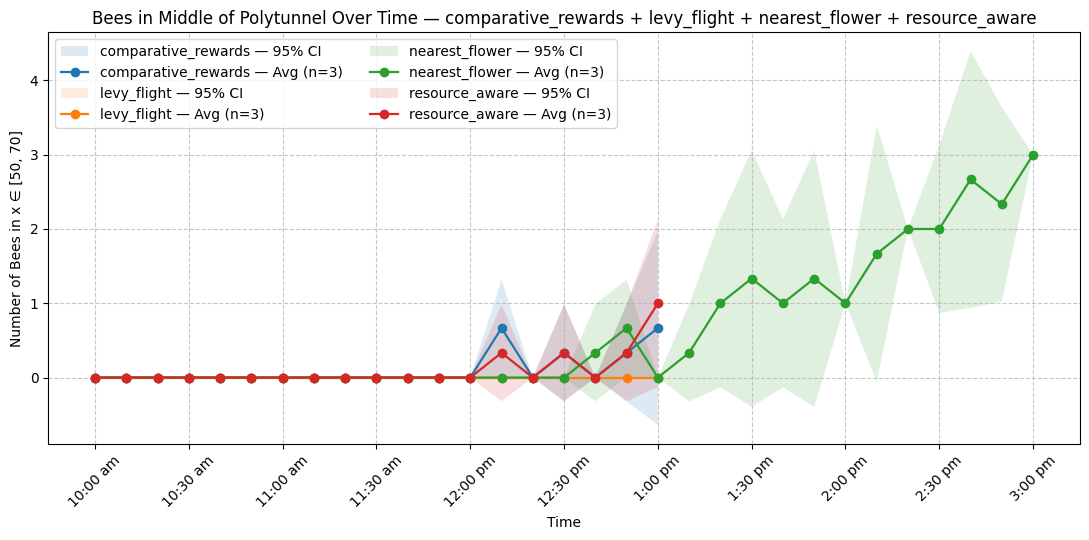

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

# ------- config -------
X_MIN, X_MAX = 50, 70
SAMPLE_EVERY = 300  # set to None or 1 to disable extra downsampling
# ---------------------

# Normalize column names that may exist under multiple aliases
CANON_MAP = {
    "interval": "interval",
    "Interval": "interval",
    "bee_behavior": "behavior",
    "Behavior": "behavior",
    "replenish_rate": "replenish_rate",
    "Replenish": "replenish_rate",
    "RewardSize": "reward_size",
}

def canonicalize_cols(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for src, dst in CANON_MAP.items():
        if src in df.columns and dst not in df.columns:
            df[dst] = df[src]
    # (Optionally) drop the duplicate source columns
    for src, dst in CANON_MAP.items():
        if src in df.columns and src != dst:
            df.drop(columns=[src], inplace=True, errors="ignore")
    if "Step" in df.columns:
        df["Step"] = df["Step"].astype(int)
    return df

# 1) Concatenate all behaviors into one DataFrame with a canonical 'behavior' column
frames = []
for beh, df in dfs_by_behavior.items():
    tmp = canonicalize_cols(df)
    # ensure 'behavior' column exists and matches the dict key (for safety)
    tmp["behavior"] = beh
    frames.append(tmp)
alldf = pd.concat(frames, ignore_index=True)

# 2) Keep Bee agents and prepare fields
bee_df = alldf[alldf["Agent Type"] == "bee"].copy()
bee_df["Step"] = bee_df["Step"].astype(int)

# Extract x coordinate from Position=(x, y)
bee_df["x"] = bee_df["Position"].apply(
    lambda pos: pos[0] if isinstance(pos, (list, tuple)) else (pos[0] if hasattr(pos, "__iter__") else np.nan)
)
bee_df = bee_df.dropna(subset=["x", "seed", "behavior"])

# Optional downsample to speed up / match other figures (note: your data is already sparse at `interval`)
if SAMPLE_EVERY and SAMPLE_EVERY > 1:
    bee_df = bee_df[bee_df["Step"] % SAMPLE_EVERY == 0]

# Flag bees inside the middle band
# (pandas >=1.3 uses inclusive="both"; if older, remove the kwarg)
bee_df["in_middle"] = bee_df["x"].between(X_MIN, X_MAX, inclusive="both")

# 3) Count per Step per seed per behavior (run-level counts)
counts_per_run = (
    bee_df.groupby(["behavior", "Step", "seed"])["in_middle"]
    .sum()
    .reset_index(name="CountInMiddle")
)

# 4) Aggregate across runs (per behavior): mean and 95% CI at each Step
stats = (
    counts_per_run.groupby(["behavior", "Step"])["CountInMiddle"]
    .agg(["mean", "std", "count"])
    .reset_index()
    .rename(columns={"mean": "AvgCount", "std": "StdDev", "count": "NumRuns"})
)
# Guard against division by zero when NumRuns==0 (shouldn't happen, but safe)
stats["CI95"] = np.where(
    stats["NumRuns"] > 0,
    1.96 * (stats["StdDev"] / np.sqrt(stats["NumRuns"])),
    0.0
)

# Helper: step -> clock time (starting 10:00)
def step_to_time_str(step):
    hh = 10 + step // 3600
    mm = (step % 3600) // 60
    suffix = "am" if hh < 12 else ("pm" if hh > 12 else "pm")
    hh12 = hh if 1 <= hh <= 12 else (hh - 12 if hh > 12 else 12)
    return f"{hh12}:{mm:02d} {suffix}"

# Build a global step axis (union of steps across behaviors)
all_steps = np.sort(stats["Step"].unique())
time_labels = [step_to_time_str(s) for s in all_steps]

# 5) Plot: one line + CI per behavior
plt.figure(figsize=(11, 5.5))

for beh in stats["behavior"].unique():
    sub = stats[stats["behavior"] == beh].sort_values("Step")

    # Shaded CI
    plt.fill_between(
        sub["Step"].to_numpy(),
        (sub["AvgCount"] - sub["CI95"]).to_numpy(),
        (sub["AvgCount"] + sub["CI95"]).to_numpy(),
        alpha=0.15,
        label=f"{beh} — 95% CI"
    )
    # Mean line (n comes from NumRuns; they should all match per behavior)
    n_runs = int(sub["NumRuns"].median()) if len(sub) else 0
    plt.plot(
        sub["Step"].to_numpy(),
        sub["AvgCount"].to_numpy(),
        marker="o",
        linewidth=1.6,
        label=f"{beh} — Avg (n={n_runs})"
    )

tick_every = max(1, len(all_steps) // 10)  # show ~10 x-ticks
plt.xticks(all_steps[::tick_every], time_labels[::tick_every], rotation=45)

plt.xlabel("Time")
plt.ylabel(f"Number of Bees in x ∈ [{X_MIN}, {X_MAX}]")
beh_list_str = " + ".join(stats["behavior"].unique())
plt.title(f"Bees in Middle of Polytunnel Over Time — {beh_list_str}")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(ncol=2, frameon=True)
plt.tight_layout()
plt.show()


# Plot: Depetion rate of nectar


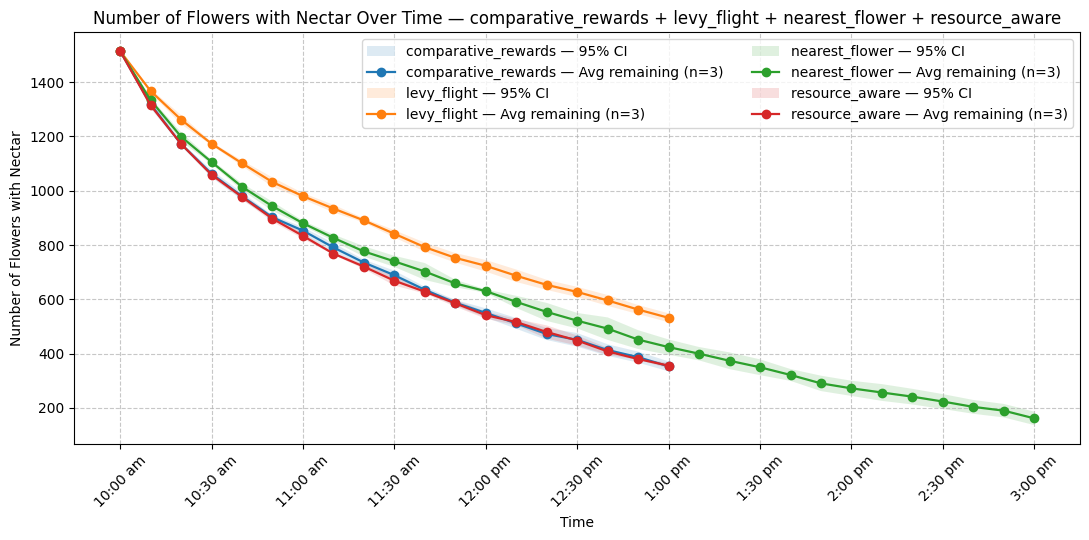

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------- CONFIG ----------------
SAMPLE_EVERY = 300        # extra downsample for speed; set to 1/None to disable
DEPLETED_EPS = 1e-9       # nectar <= eps is considered depleted
# ---------------------------------------

# Map possibly-duplicated names to a canonical one
CANON_MAP = {
    "interval": "interval",
    "Interval": "interval",
    "bee_behavior": "behavior",
    "Behavior": "behavior",
    "replenish_rate": "replenish_rate",
    "Replenish": "replenish_rate",
    "RewardSize": "reward_size",
}

def canonicalize_cols(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for src, dst in CANON_MAP.items():
        if src in df.columns and dst not in df.columns:
            df[dst] = df[src]
    # (optionally) drop dup source columns
    for src, dst in CANON_MAP.items():
        if src in df.columns and src != dst:
            df.drop(columns=[src], inplace=True, errors="ignore")
    if "Step" in df.columns:
        df["Step"] = df["Step"].astype(int)
    return df

# 1) Concatenate all behaviors into one DataFrame with a canonical 'behavior' column
frames = []
for beh, df in dfs_by_behavior.items():
    tmp = canonicalize_cols(df)
    tmp["behavior"] = beh  # ensure it matches the key
    frames.append(tmp)
alldf = pd.concat(frames, ignore_index=True)

# 2) Keep Plant agents, prep fields
plant_df = alldf[alldf["Agent Type"] == "plant"].copy()
plant_df["Step"] = plant_df["Step"].astype(int)
plant_df = plant_df.dropna(subset=["Plant nectar amount", "seed", "behavior"])

# Optional extra downsample (your data is already sparse at `interval`, but this can speed up further)
if SAMPLE_EVERY and SAMPLE_EVERY > 1:
    plant_df = plant_df[plant_df["Step"] % SAMPLE_EVERY == 0]

# Remaining = flowers with nectar > eps
plant_df["is_remaining"] = plant_df["Plant nectar amount"] > DEPLETED_EPS

# 3) Count remaining per (behavior, Step, seed)
rem_counts_per_run = (
    plant_df.groupby(["behavior", "Step", "seed"])["is_remaining"]
    .sum()
    .reset_index(name="NumRemaining")
)

# 4) Aggregate across runs: mean & 95% CI per behavior-step
stats = (
    rem_counts_per_run.groupby(["behavior", "Step"])["NumRemaining"]
    .agg(["mean", "std", "count"])
    .reset_index()
    .rename(columns={"mean": "AvgRemaining", "std": "StdDev", "count": "NumRuns"})
)
stats["CI95"] = np.where(
    stats["NumRuns"] > 0,
    1.96 * (stats["StdDev"] / np.sqrt(stats["NumRuns"])),
    0.0
)

# Helper: step -> clock time (start at 10:00)
def step_to_time_str(step):
    hh = 10 + step // 3600
    mm = (step % 3600) // 60
    suffix = "am" if hh < 12 else ("pm" if hh > 12 else "pm")
    hh12 = hh if 1 <= hh <= 12 else (hh - 12 if hh > 12 else 12)
    return f"{hh12}:{mm:02d} {suffix}"

all_steps = np.sort(stats["Step"].unique())
time_labels = [step_to_time_str(s) for s in all_steps]

# 5) Plot: Remaining flowers over time (per behavior)
plt.figure(figsize=(11, 5.5))

for beh in stats["behavior"].unique():
    sub = stats[stats["behavior"] == beh].sort_values("Step")
    n_runs = int(sub["NumRuns"].median()) if len(sub) else 0

    # 95% CI band
    plt.fill_between(
        sub["Step"].to_numpy(),
        (sub["AvgRemaining"] - sub["CI95"]).to_numpy(),
        (sub["AvgRemaining"] + sub["CI95"]).to_numpy(),
        alpha=0.15,
        label=f"{beh} — 95% CI"
    )
    # Mean line
    plt.plot(
        sub["Step"].to_numpy(),
        sub["AvgRemaining"].to_numpy(),
        marker="o",
        linewidth=1.6,
        label=f"{beh} — Avg remaining (n={n_runs})"
    )

tick_every = max(1, len(all_steps) // 10)
plt.xticks(all_steps[::tick_every], time_labels[::tick_every], rotation=45)

plt.xlabel("Time")
plt.ylabel("Number of Flowers with Nectar")
beh_list_str = " + ".join(stats["behavior"].unique())
plt.title(f"Number of Flowers with Nectar Over Time — {beh_list_str}")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(ncol=2, frameon=True)
plt.tight_layout()
plt.show()


# Plot: The change in likelihood in making a long jump

X-axis: time of the simulation

Y-axis: the probability of a bee making a long jump

In [11]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt

# def plot_long_jump_likelihood_by_behavior(
#     data,
#     long_jump_threshold=None,   # required if "Long jump" is NOT present
#     smooth_window=60,
#     show_policy=True,
# ):
#     """
#     data: either
#       - dict[str, DataFrame] mapping behavior -> df  (we add 'behavior' and concat), or
#       - a single DataFrame that already has 'behavior'
#     Assumes the rows are agent-time snapshots collected by Mesa's DataCollector.

#     Required columns: 'Agent Type', 'Step', 'Position'
#     Recommended: 'seed' (for CI)
#     Optional: 'Long jump' (bool), 'Reward window mean' (float)
#     """

#     # ---- unify input ----
#     if isinstance(data, dict):
#         frames = []
#         for beh, df in data.items():
#             tmp = df.copy()
#             tmp["behavior"] = beh
#             frames.append(tmp)
#         alldf = pd.concat(frames, ignore_index=True)
#     else:
#         alldf = data.copy()
#         if "behavior" not in alldf.columns:
#             raise ValueError("When passing a single DataFrame, it must include a 'behavior' column.")

#     # bees only
#     bee = alldf[alldf["Agent Type"] == "bee"].copy().reset_index(drop=True)
#     if "Step" not in bee.columns:
#         raise ValueError("Missing 'Step' column.")
#     bee["Step"] = bee["Step"].astype(int)

#     # ensure 'seed' exists for CI; if not, create a dummy
#     if "seed" not in bee.columns:
#         bee["seed"] = 0

#     # ---- realized rate ----
#     if "Long jump" in bee.columns:
#         bee["is_long"] = bee["Long jump"].astype(bool)
#     else:
#         if long_jump_threshold is None:
#             raise ValueError("No 'Long jump' column; provide long_jump_threshold to derive from positions.")
#         # sort for proper deltas within behavior/seed/bee
#         bee = bee.sort_values(["behavior", "seed", "unique_id", "Step"]).copy()
#         prev_pos = bee.groupby(["behavior", "seed", "unique_id"])["Position"].shift(1)

#         def _dist(p, q):
#             if (p is None) or (q is None):
#                 return np.nan
#             x1, y1 = p; x2, y2 = q
#             return ((x2 - x1)**2 + (y2 - y1)**2) ** 0.5

#         bee["step_len"] = [_dist(p, q) for p, q in zip(bee["Position"], prev_pos)]
#         bee["is_long"] = bee["step_len"] > float(long_jump_threshold)

#     realized_per_run = (
#         bee.dropna(subset=["is_long"])
#            .groupby(["behavior", "seed", "Step"])["is_long"]
#            .mean()
#            .reset_index(name="RealizedRate")
#     )

#     realized_stats = (
#         realized_per_run.groupby(["behavior", "Step"])["RealizedRate"]
#         .agg(['mean', 'std', 'count'])
#         .reset_index()
#         .rename(columns={'mean':'RealizedMean','std':'RealizedStd','count':'NumRuns'})
#     )
#     realized_stats["RealizedCI95"] = 1.96 * (realized_stats["RealizedStd"] / realized_stats["NumRuns"].clip(lower=1).pow(0.5))
#     realized_stats = realized_stats.sort_values(["behavior", "Step"])
#     realized_stats["RealizedSmooth"] = (
#         realized_stats.groupby("behavior")["RealizedMean"]
#         .transform(lambda s: s.rolling(smooth_window, min_periods=1).mean())
#     )
#     realized_stats["RealizedLow"]  = (realized_stats["RealizedMean"] - realized_stats["RealizedCI95"]).clip(lower=0)
#     realized_stats["RealizedHigh"] = (realized_stats["RealizedMean"] + realized_stats["RealizedCI95"]).clip(upper=1)

#     # ---- policy-implied propensity (optional) ----
#     policy_stats = None
#     if show_policy and ("Reward window mean" in bee.columns):
#         pol = bee[~bee["Reward window mean"].isna()].copy()
#         if len(pol):
#             pol["Propensity"] = 1.0 - pol["Reward window mean"].astype(float)
#             policy_per_run = (
#                 pol.groupby(["behavior", "seed", "Step"])["Propensity"]
#                    .mean().reset_index(name="PolicyProp")
#             )
#             policy_stats = (
#                 policy_per_run.groupby(["behavior","Step"])["PolicyProp"]
#                 .agg(['mean','std','count']).reset_index()
#                 .rename(columns={'mean':'PolicyMean','std':'PolicyStd','count':'NumRuns'})
#             )
#             policy_stats["PolicyCI95"] = 1.96 * (policy_stats["PolicyStd"] / policy_stats["NumRuns"].clip(lower=1).pow(0.5))
#             policy_stats = policy_stats.sort_values(["behavior","Step"])
#             policy_stats["PolicySmooth"] = (
#                 policy_stats.groupby("behavior")["PolicyMean"]
#                 .transform(lambda s: s.rolling(smooth_window, min_periods=1).mean())
#             )

#     # ---- plot ----
#     plt.figure(figsize=(11,6))
#     for beh in realized_stats["behavior"].unique():
#         sub_r = realized_stats[realized_stats["behavior"] == beh]
#         n_runs = int(sub_r["NumRuns"].median()) if len(sub_r) else 0

#         # shaded CI + smoothed realized line
#         plt.fill_between(sub_r["Step"], sub_r["RealizedLow"], sub_r["RealizedHigh"],
#                          alpha=0.12, label=f"{beh} — Realized 95% CI")
#         plt.plot(sub_r["Step"], sub_r["RealizedSmooth"], linewidth=1.8,
#                  label=f"{beh} — Realized (n={n_runs})")

#         # policy line (if available)
#         if policy_stats is not None:
#             sub_p = policy_stats[policy_stats["behavior"] == beh]
#             if len(sub_p):
#                 plt.plot(sub_p["Step"], sub_p["PolicySmooth"], linestyle="--", alpha=0.9,
#                          label=f"{beh} — Policy (1 - reward mean)")

#     plt.ylim(0, 1)
#     plt.xlabel("Step (s)")
#     plt.ylabel("Probability / Fraction")
#     plt.title("Likelihood of Long Jumps Over Time — by Behavior")
#     plt.grid(True, linestyle="--", alpha=0.5)
#     plt.legend(ncol=2, frameon=True)
#     plt.tight_layout()
#     plt.show()


In [12]:
# plot_long_jump_likelihood_by_behavior(dfs_by_behavior, smooth_window=60)

# Mark Hall's data

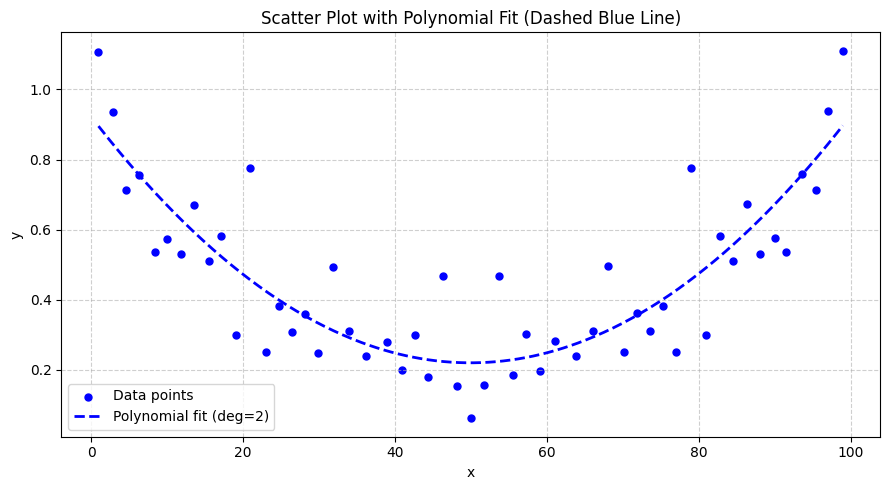

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Data points from Mark Hall paper using datatheif
points = [
(0.9582, 1.1066), (2.909, 0.9346), (4.5806, 0.7119), (6.307, 0.7557), 
(8.4371, 0.535), (9.9521, 0.5739), (11.7543, 0.5301), (13.5809, 0.6703), 
(15.531, 0.5112), (17.0441, 0.5819), (19.0367, 0.3006), (20.8789, 0.7749), 
(22.9562, 0.252), (24.7128, 0.3822), (26.4462, 0.3087), (28.1723, 0.3585), 
(29.8371, 0.249), (31.8694, 0.4928), (33.8914, 0.3099), (36.1186, 0.2393), 
(38.9038, 0.2791), (40.8492, 0.1997), (42.6076, 0.3001), (44.3436, 0.1808), 
(46.3028, 0.4672), (48.1561, 0.1541), (49.9611, 0.0616), (51.7198, 0.1561), 
(53.607, 0.4673), (55.5643, 0.185), (57.2159, 0.3014), (59.0921, 0.198), 
(61.0279, 0.2816), (63.818, 0.2389), (66.0368, 0.3094), (68.0724, 0.4965), 
(70.0982, 0.2509), (71.8559, 0.3623), (73.482, 0.3117), (75.2774, 0.3833), 
(77.0141, 0.2521), (78.9592, 0.777), (80.8575, 0.2989), (82.8169, 0.5823), 
(84.4443, 0.5097), (86.3048, 0.6728), (88.0774, 0.5316), (89.9449, 0.5754), 
(91.4646, 0.5356), (93.4981, 0.7584), (95.3356, 0.7137), (96.9456, 0.9375), 
(98.9114, 1.1105),]

# Sort and prepare
df = pd.DataFrame(points, columns=["x", "y"]).sort_values("x").reset_index(drop=True)
x, y = df["x"].values, df["y"].values

# Polynomial fit
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)

# Smooth curve
x_fit = np.linspace(min(x), max(x), 400)
y_fit = poly_func(x_fit)

# Plot
plt.figure(figsize=(9, 5))
plt.scatter(x, y, color="blue", s=25, label="Data points")
plt.plot(x_fit, y_fit, linestyle="--", color="blue", linewidth=2.0, label=f"Polynomial fit (deg={degree})")
plt.title("Scatter Plot with Polynomial Fit (Dashed Blue Line)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()
